# LAB1 - Phần 2 - Bài 6 (Trang 45): Apriori vs FP-Growth trên Groceries Dataset
**Phạm Quốc Thuận - 6451071076 - CNTT.64**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth
import warnings
warnings.filterwarnings('ignore')

## Đọc dữ liệu và chuyển về one-hot encoding (TransactionEncoder)

In [2]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
with open('../Dataset/groceries.csv', encoding='utf-8') as f:
    transactions = [line.strip().split(',') for line in f if line.strip()]
te = TransactionEncoder()
df = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print('Số giao dịch:', df.shape[0], '| Số items:', df.shape[1])
# min_sup từ 0.01% đến 0.1% (bước 0.01%)
MIN_SUPS = [round(0.0001 * i, 4) for i in range(1, 11)]
# Ở min_sup = 0.01% chỉ cần 1 giao dịch là thành tập phổ biến -> số tập phổ biến bùng nổ (2^32 tập con)
# nên giới hạn độ dài tập phổ biến tối đa MAX_LEN = 3 cho cả 2 thuật toán để so sánh công bằng
MAX_LEN = 3
print('Các ngưỡng min_sup:', [f'{s*100:.2f}%' for s in MIN_SUPS])
df.iloc[:5, :8]

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số giao dịch: 9835 | Số items: 169
Các ngưỡng min_sup: ['0.01%', '0.02%', '0.03%', '0.04%', '0.05%', '0.06%', '0.07%', '0.08%', '0.09%', '0.10%']


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


## Câu a: Tìm tập phổ biến bằng Apriori với từng min_sup và ghi nhận thời gian

In [3]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
apriori_result = []
for s in MIN_SUPS:
    start = time.time()
    fi = apriori(df, min_support=s, use_colnames=True, low_memory=True, max_len=MAX_LEN)
    t = time.time() - start
    apriori_result.append({'min_sup (%)': round(s * 100, 2), 'so_tap_pho_bien': len(fi), 'thoi_gian_s': round(t, 3)})
    print(f'min_sup = {s*100:.2f}% -> {len(fi):>7} tập phổ biến, thời gian {t:.3f} s')
apriori_df = pd.DataFrame(apriori_result)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


min_sup = 0.01% ->  149229 tập phổ biến, thời gian 1.066 s


min_sup = 0.02% ->   70858 tập phổ biến, thời gian 0.720 s


min_sup = 0.03% ->   44260 tập phổ biến, thời gian 0.479 s


min_sup = 0.04% ->   31576 tập phổ biến, thời gian 0.371 s


min_sup = 0.05% ->   24172 tập phổ biến, thời gian 0.330 s


min_sup = 0.06% ->   19251 tập phổ biến, thời gian 0.372 s


min_sup = 0.07% ->   15844 tập phổ biến, thời gian 0.251 s


min_sup = 0.08% ->   13340 tập phổ biến, thời gian 0.230 s
min_sup = 0.09% ->   11438 tập phổ biến, thời gian 0.206 s


min_sup = 0.10% ->    9969 tập phổ biến, thời gian 0.178 s


## Câu b: Tìm tập phổ biến bằng FP-Growth với từng min_sup và ghi nhận thời gian

In [4]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
fp_result = []
for s in MIN_SUPS:
    start = time.time()
    fi = fpgrowth(df, min_support=s, use_colnames=True, max_len=MAX_LEN)
    t = time.time() - start
    fp_result.append({'min_sup (%)': round(s * 100, 2), 'so_tap_pho_bien': len(fi), 'thoi_gian_s': round(t, 3)})
    print(f'min_sup = {s*100:.2f}% -> {len(fi):>7} tập phổ biến, thời gian {t:.3f} s')
fp_df = pd.DataFrame(fp_result)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


min_sup = 0.01% ->  149229 tập phổ biến, thời gian 2.792 s


min_sup = 0.02% ->   70858 tập phổ biến, thời gian 1.474 s


min_sup = 0.03% ->   44260 tập phổ biến, thời gian 1.175 s


min_sup = 0.04% ->   31576 tập phổ biến, thời gian 0.771 s


min_sup = 0.05% ->   24172 tập phổ biến, thời gian 0.764 s


min_sup = 0.06% ->   19251 tập phổ biến, thời gian 0.601 s


min_sup = 0.07% ->   15844 tập phổ biến, thời gian 0.515 s


min_sup = 0.08% ->   13340 tập phổ biến, thời gian 0.503 s


min_sup = 0.09% ->   11438 tập phổ biến, thời gian 0.471 s


min_sup = 0.10% ->    9969 tập phổ biến, thời gian 0.437 s


## Câu c: Biểu đồ so sánh thời gian xử lý của hai thuật toán

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,min_sup (%),so_tap_pho_bien_apriori,thoi_gian_s_apriori,so_tap_pho_bien_fpgrowth,thoi_gian_s_fpgrowth
0,0.01,149229,1.066,149229,2.792
1,0.02,70858,0.720,70858,1.474
2,0.03,44260,0.479,44260,1.175
3,0.04,31576,0.371,31576,0.771
4,0.05,24172,0.330,24172,0.764
5,0.06,19251,0.372,19251,0.601
6,0.07,15844,0.251,15844,0.515
7,0.08,13340,0.230,13340,0.503
8,0.09,11438,0.206,11438,0.471
9,0.10,9969,0.178,9969,0.437


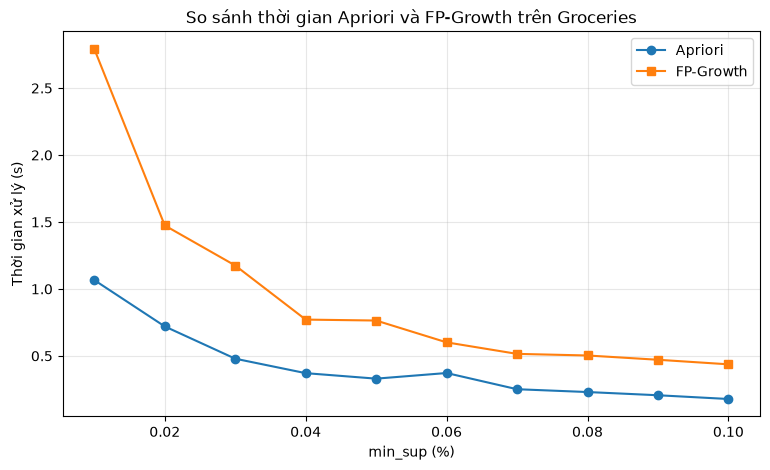

In [5]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
compare = apriori_df.merge(fp_df, on='min_sup (%)', suffixes=('_apriori', '_fpgrowth'))
display(compare)
plt.figure(figsize=(9, 5))
plt.plot(compare['min_sup (%)'], compare['thoi_gian_s_apriori'], 'o-', label='Apriori')
plt.plot(compare['min_sup (%)'], compare['thoi_gian_s_fpgrowth'], 's-', label='FP-Growth')
plt.xlabel('min_sup (%)'); plt.ylabel('Thời gian xử lý (s)')
plt.title('So sánh thời gian Apriori và FP-Growth trên Groceries')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Mở rộng (minh họa thêm cho Câu c): so sánh khi KHÔNG giới hạn độ dài tập phổ biến

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,min_sup (%),so_tap,apriori_s,fpgrowth_s
0,0.10,13492,0.451,0.440
1,0.08,19979,0.845,0.509
2,0.06,34353,1.361,0.736
3,0.05,49580,2.131,0.905
4,0.04,80388,4.068,1.143
5,0.03,166682,12.954,1.943


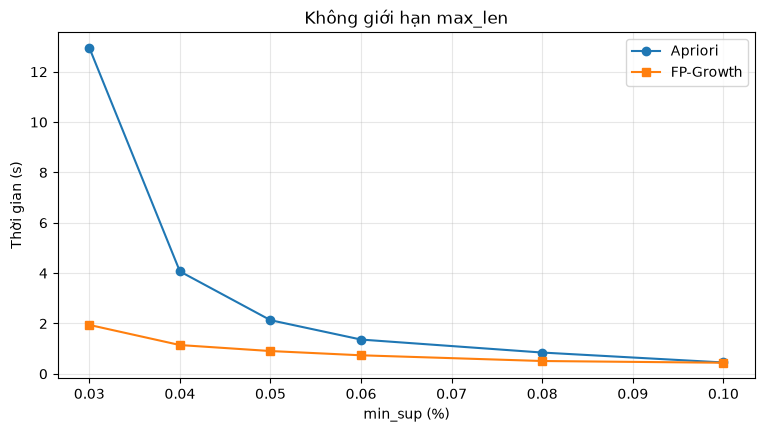

In [6]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
ext = []
for s in [0.001, 0.0008, 0.0006, 0.0005, 0.0004, 0.0003]:
    t0 = time.time(); n_ap = len(apriori(df, min_support=s, use_colnames=True, low_memory=True)); t_ap = time.time() - t0
    t0 = time.time(); n_fp = len(fpgrowth(df, min_support=s, use_colnames=True)); t_fp = time.time() - t0
    ext.append({'min_sup (%)': s * 100, 'so_tap': n_ap, 'apriori_s': round(t_ap, 3), 'fpgrowth_s': round(t_fp, 3)})
ext = pd.DataFrame(ext); display(ext)
plt.figure(figsize=(9, 4.5))
plt.plot(ext['min_sup (%)'], ext['apriori_s'], 'o-', label='Apriori')
plt.plot(ext['min_sup (%)'], ext['fpgrowth_s'], 's-', label='FP-Growth')
plt.xlabel('min_sup (%)'); plt.ylabel('Thời gian (s)'); plt.title('Không giới hạn max_len')
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Nhận xét & Giải thích:**
- **Về kết quả:** Ở mọi ngưỡng `min_sup` từ `0.01%` đến `0.10%`, cả **Apriori** và **FP-Growth** đều tìm ra **cùng số lượng tập phổ biến** (ví dụ: 9.969 tập ở `0.10%` và tăng lên 149.229 tập ở `0.01%` khi `max_len = 3`; hoặc 13.492 tập ở `0.10%` lên 166.682 tập ở `0.03%` khi không giới hạn `max_len`). Khi `min_sup` càng giảm, số tập phổ biến tăng lên theo hàm mũ nên thời gian xử lý của cả hai thuật toán đều tăng.
- **So sánh và giải thích tốc độ giữa hai thuật toán:**
  1. **Khi không giới hạn độ dài tập phổ biến (các tập phổ biến dài tới 7–10 phần tử):** **FP-Growth nhanh vượt trội so với Apriori** và khoảng cách càng lớn khi `min_sup` giảm (tại `min_sup = 0.03%`, FP-Growth chỉ mất **~1,94 giây** trong khi Apriori mất **~12,95 giây**, nhanh hơn gần **6,7 lần**). Nguyên nhân là Apriori phải sinh tập ứng viên $C_k$ theo từng mức $k$ và quét lại cơ sở dữ liệu nhiều lần (chi phí tổ hợp tăng bùng nổ khi nhiều tập dài), còn FP-Growth chỉ quét dữ liệu đúng 2 lần để nén toàn bộ giao dịch vào cấu trúc **FP-Tree** và khai thác đệ quy trên cây điều kiện mà **không cần sinh ứng viên**.
  2. **Khi giới hạn tập ngắn (`max_len = 3` để chạy tới `min_sup = 0.01%`, tương ứng chỉ 1 giao dịch trên 9.835 giao dịch):** Trong thư viện `mlxtend`, Apriori dùng phép nhân/AND vector hóa của NumPy ở mức C chỉ qua 3 vòng lặp ngắn ($k = 1, 2, 3$) nên thời gian hơi thấp hơn FP-Growth (1,07 giây so với 2,79 giây ở `0.01%`), vốn phải dựng cây và cấp phát nhiều đối tượng nút trên Python.